# Figure 2 — benchmarking and external validation

Plotting-only reproduction of panels A–H from frozen, checksummed inputs. Statistical annotations are generated separately by `analysis/derive_annotations.py`.


## Interpretation

Figure 2 compares runtime, knowledge capacity, clustering agreement, and external Hallmark behavior. `bgNMF` in the historical runtime table is the method now named scKNIFE.


Validated 24 inputs and 13 UMAP schemas/checksums (matplotlib fallback; cnsplots unavailable in Python 3.9 environment).


,file,cells,clusters,author_types
0,expimap_bassez_c1_umap.csv.gz,81142,2,8
1,expimap_bassez_c2_umap.csv.gz,36264,6,8
2,expimap_wu_tnbc_umap.csv.gz,38251,11,9
3,scknife_bassez_c1_umap.csv.gz,82120,8,8
4,scknife_bassez_c2_umap.csv.gz,36721,8,8
5,scknife_shiao_umap.csv.gz,262070,9,8
6,scknife_wu_tnbc_umap.csv.gz,42512,9,9
7,slalom_bassez_c1_umap.csv.gz,81142,6,8
8,slalom_bassez_c2_umap.csv.gz,36264,18,8
9,slalom_wu_tnbc_umap.csv.gz,38251,6,9


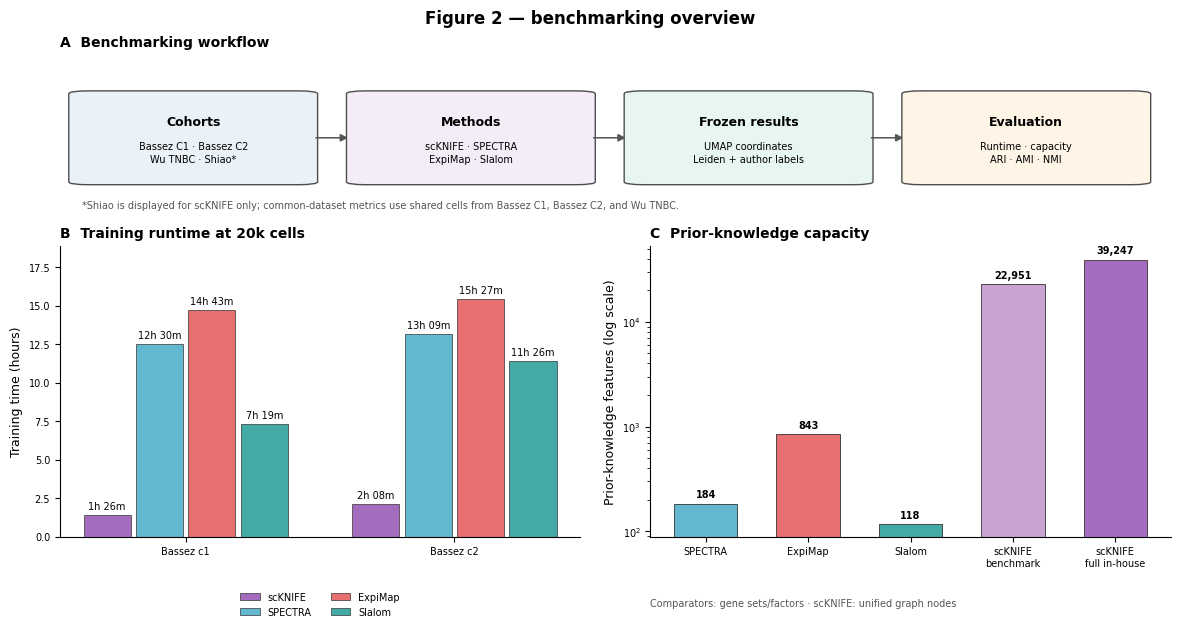

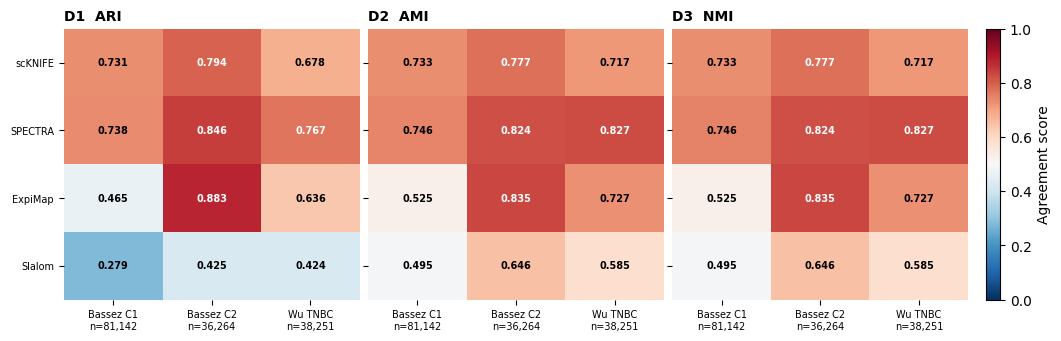

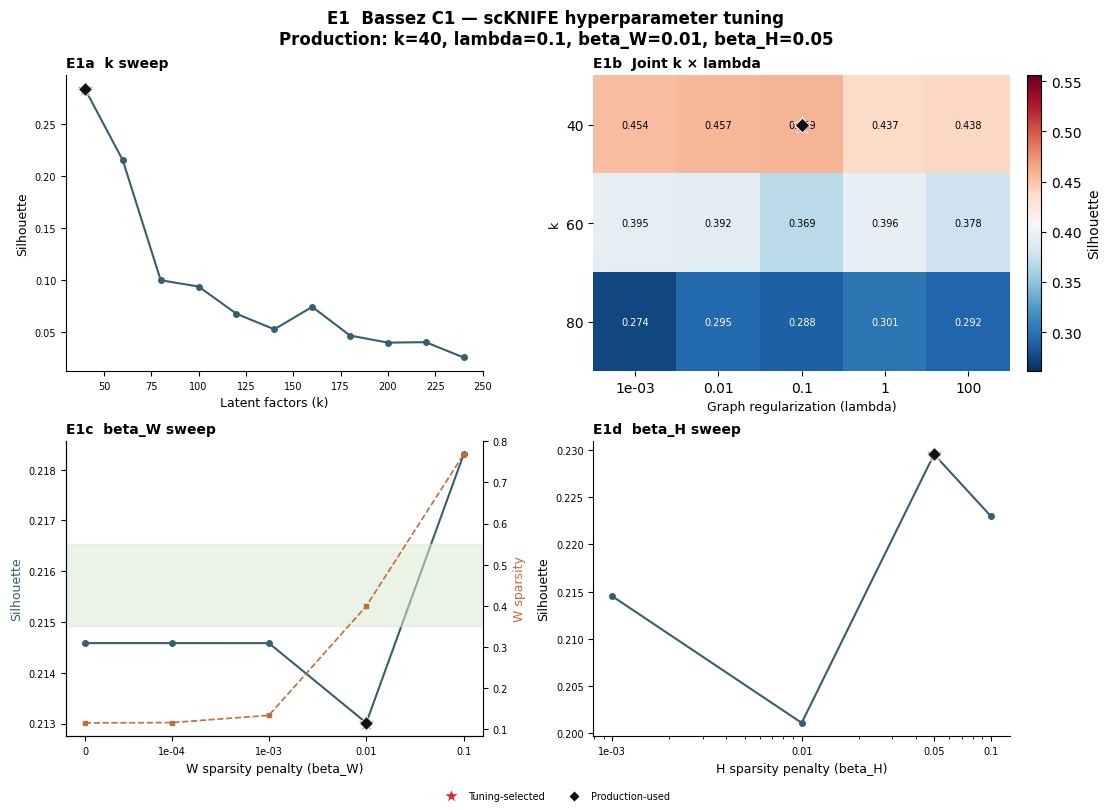

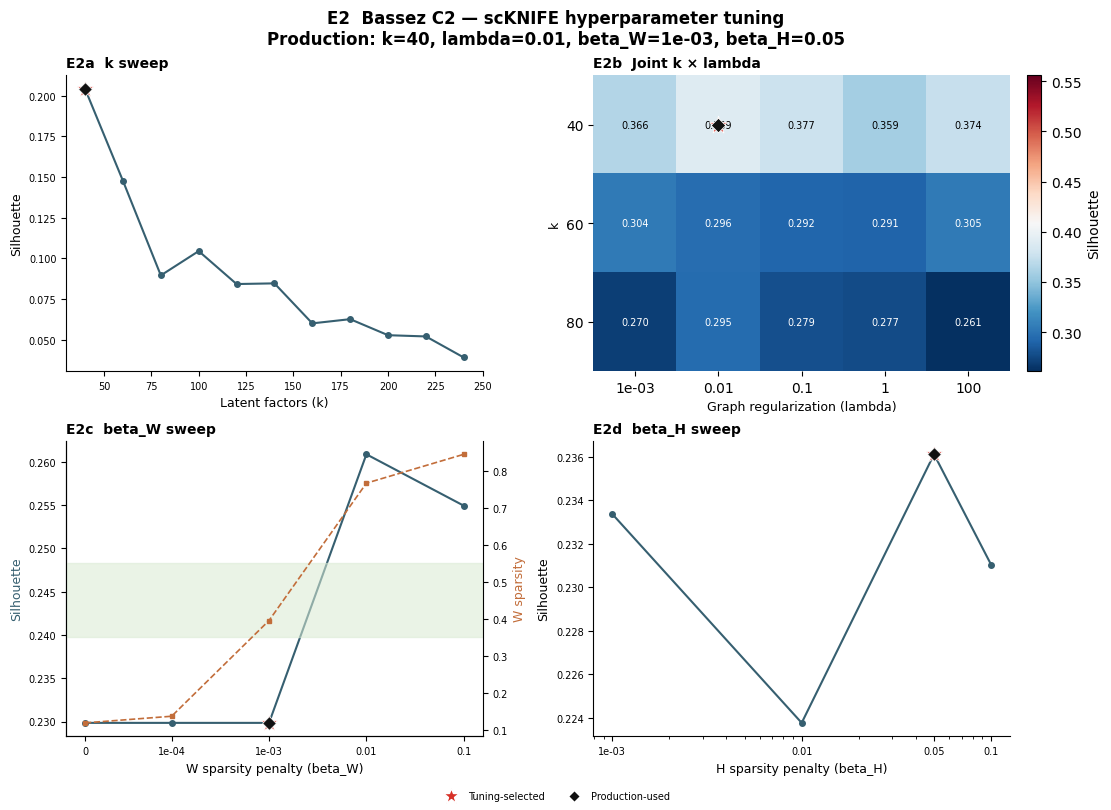

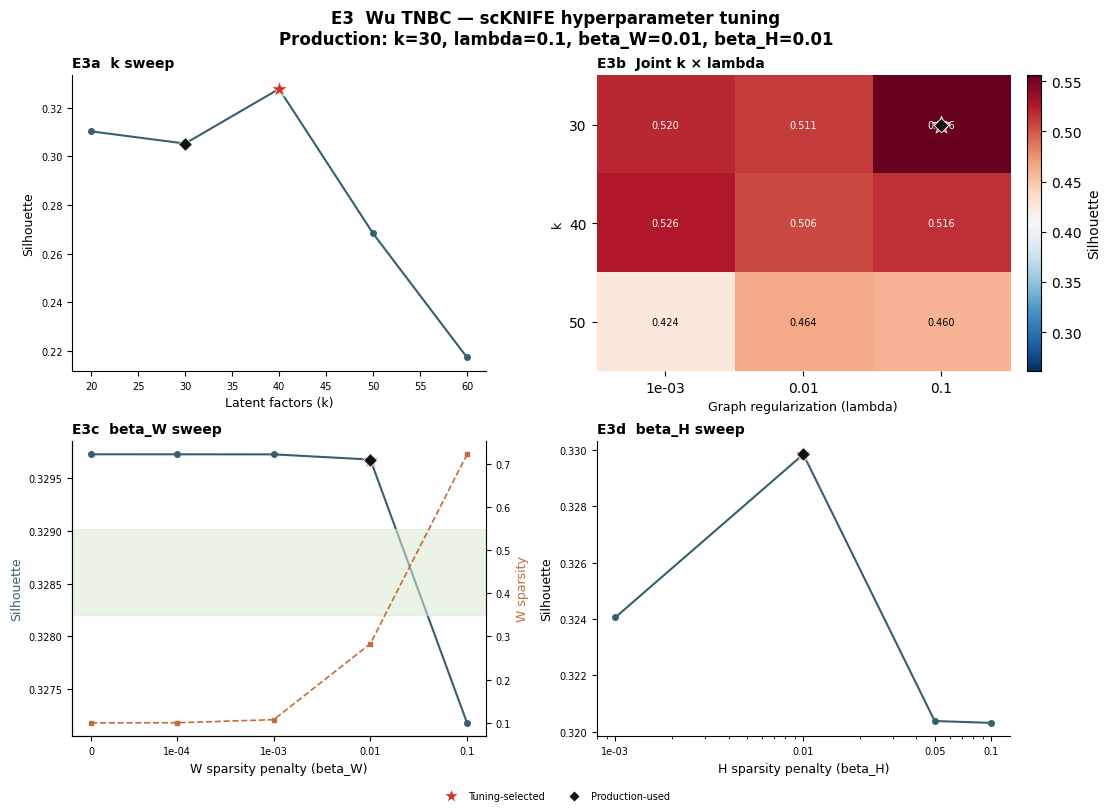

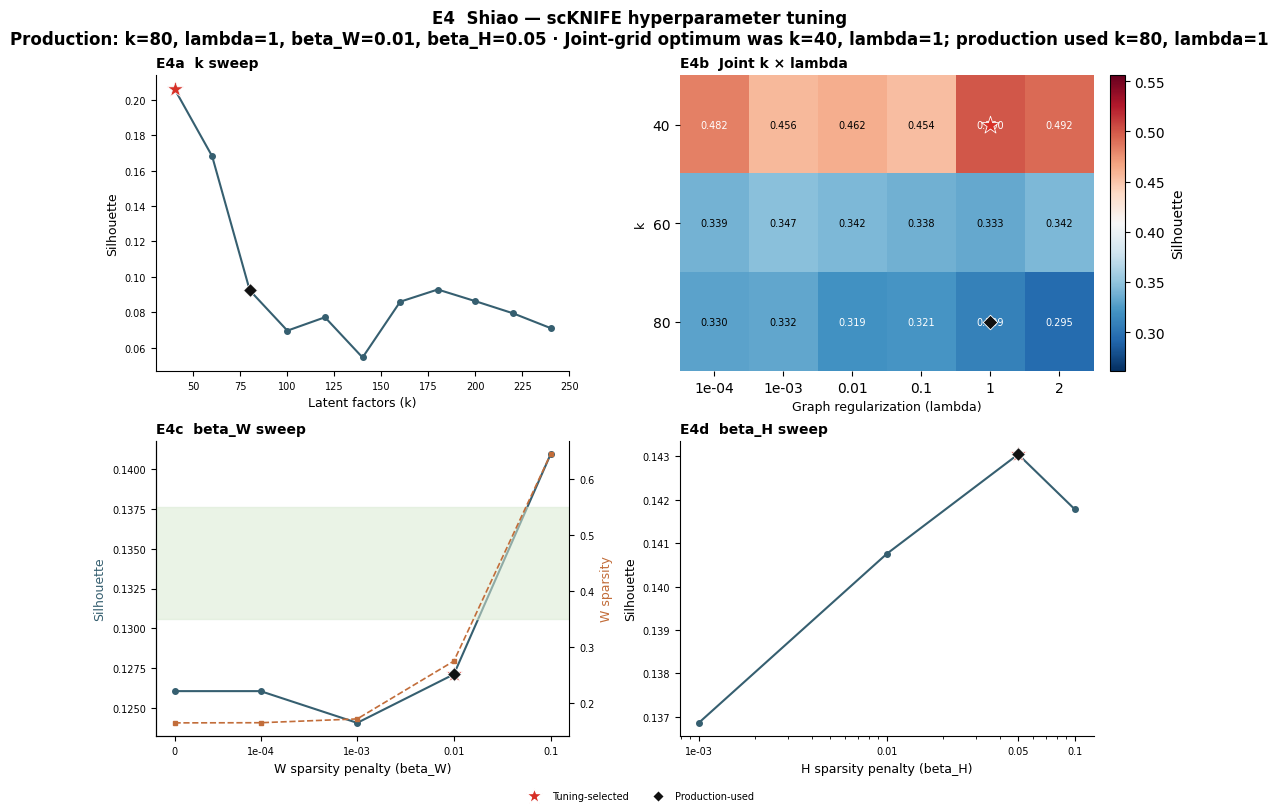

Loaded 24 frozen source files


In [1]:
%matplotlib inline
from pathlib import Path
from IPython.display import display
from plotting import *
OUTPUT_DIR=Path("outputs"); OUTPUT_DIR.mkdir(exist_ok=True)
print(f"Loaded {len(manifest['files'])} frozen source files")


## Input audit


In [2]:
display(runtime_df.sort_values(["dataset","method"]))
display(capacity_df)
display(agreement_df)
display(hallmark_correlations)
display(tuning_final_df)


,method,dataset,seconds,hours
4,ExpiMap,Bassez c1,52989.46,14.719294
2,SPECTRA,Bassez c1,44970.52,12.491811
6,Slalom,Bassez c1,26357.98,7.321661
0,scKNIFE,Bassez c1,5184.97,1.440269
5,ExpiMap,Bassez c2,55620.43,15.450119
3,SPECTRA,Bassez c2,47312.88,13.142467
7,Slalom,Bassez c2,41150.61,11.430725
1,scKNIFE,Bassez c2,7662.84,2.128567


,method,scope,feature_type,count
0,SPECTRA,Benchmarking,Gene sets/factors,184
1,ExpiMap,Benchmarking,Gene sets,843
2,Slalom,Benchmarking,Gene sets,118
3,scKNIFE,Benchmarking graph,Unified graph nodes,22951
4,scKNIFE,Full in-house graph,Unified graph nodes,39247


,method,dataset,n_shared,n_clusters,n_author_types,ari,ami,nmi
0,scKNIFE,bassez_c1,81142,8,8,0.731139,0.733217,0.733267
1,SPECTRA,bassez_c1,81142,9,8,0.737949,0.746092,0.746145
2,ExpiMap,bassez_c1,81142,2,8,0.464982,0.525043,0.525061
3,Slalom,bassez_c1,81142,6,8,0.278529,0.495176,0.495258
4,scKNIFE,bassez_c2,36264,8,8,0.794461,0.776668,0.776756
5,SPECTRA,bassez_c2,36264,7,8,0.845561,0.824130,0.824191
6,ExpiMap,bassez_c2,36264,6,8,0.882710,0.834775,0.834825
7,Slalom,bassez_c2,36264,18,8,0.425324,0.646118,0.646388
8,scKNIFE,wu_tnbc,38251,9,9,0.678275,0.716766,0.716892
9,SPECTRA,wu_tnbc,38251,14,9,0.767390,0.826852,0.826967


,gene,score,n,pearson_r,spearman_rho
0,TP53,scKNIFE,64064,0.646438,0.537118
1,TP53,Scanpy,64064,0.625616,0.398477
2,PIK3R1,scKNIFE,60743,0.764831,0.702650
3,PIK3R1,Scanpy,60743,0.744909,0.695917


,dataset,k,lambda_reg,beta_W,beta_H,n_iter
0,Bassez C1,40,0.10,0.010,0.05,500
1,Bassez C2,40,0.01,0.001,0.05,500
2,Wu TNBC,30,0.10,0.010,0.01,500
3,Shiao,80,1.00,0.010,0.05,500


## Individual panels


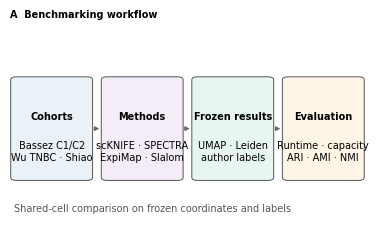

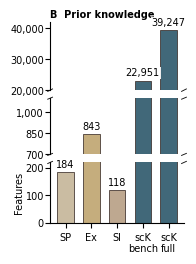

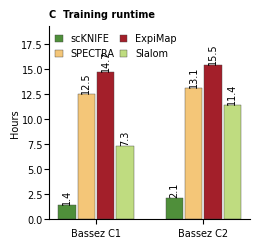

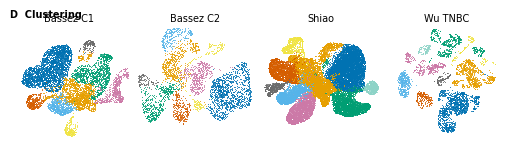

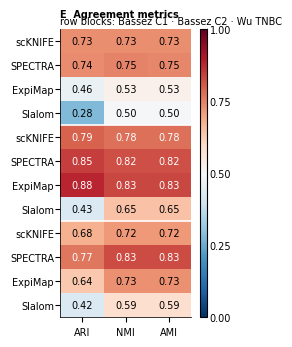

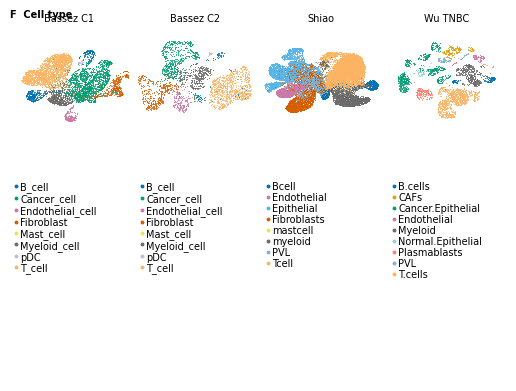

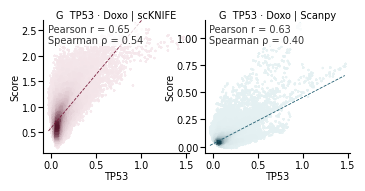

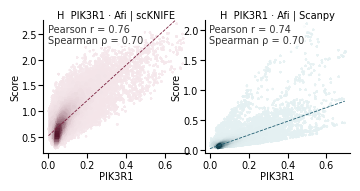

In [3]:
for label in "ABCDEFGH":
    panel=make_figure2_panel(label)
    display(panel)
    plt.close(panel)


## Compiled Figure 2


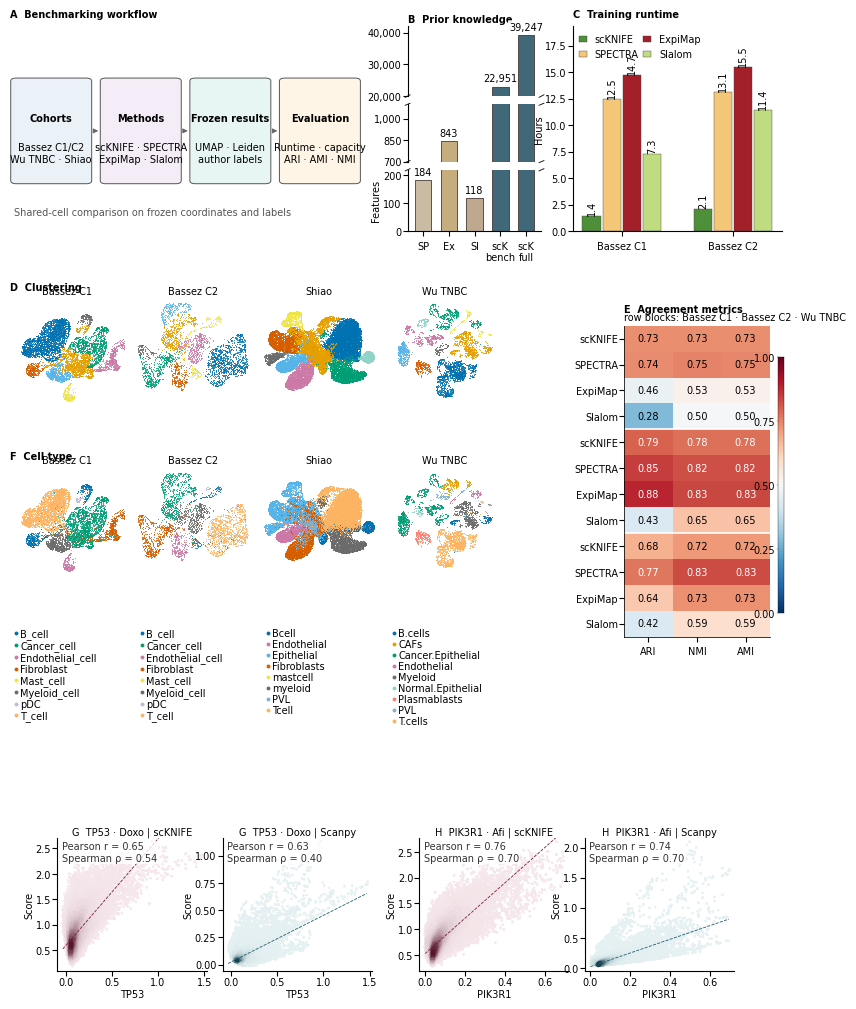

outputs/Figure_2.pdf outputs/Figure_2_preview.png


In [4]:
figure, raster_assets=make_figure2_runtime_preview()
pdf=OUTPUT_DIR/"Figure_2.pdf"
png=OUTPUT_DIR/"Figure_2_preview.png"
figure.savefig(pdf,format="pdf",dpi=OUTPUT_DPI,facecolor="white")
figure.savefig(png,format="png",dpi=OUTPUT_DPI,facecolor="white")
display(figure); plt.close(figure)
print(pdf, png)
